# 02 — Data Prep | Bank Marketing

Transforma a base bruta em bases de **treino, teste e out-of-time (OOT)** prontas para modelar.

**Regra de ouro:** tudo que "aprende" com os dados (mediana, moda, target encoder, scaler) é ajustado **só no treino** e depois aplicado no teste e no OOT. Assim nenhuma informação do teste vaza para o modelo.

**Etapas**
1. Setup e leitura
2. Limpeza (duplicatas, `duration`, target 0/1)
3. Coluna `AnoMes`
4. Variáveis novas
5. Split: OOT por tempo + treino/teste estratificado
6. Imputação (nulos → mediana · `unknown` → moda)
7. Target Encoding das categóricas
8. Padronização (StandardScaler)
9. Checagens finais
10. Salvar bases e transformadores

## 1. Setup e leitura

In [29]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import TargetEncoder, StandardScaler

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

SEED = 42

In [30]:
from google.colab import drive
drive.mount('/content/drive')
PASTA = r'/content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario'
file_path_base = f'{PASTA}/Base/bank-additional-full.csv'
PASTA_SAIDA = f'{PASTA}/Base/prep'


import os
os.makedirs(PASTA_SAIDA, exist_ok=True)

df_base = pd.read_csv(file_path_base, sep=';')
print(f'Base bruta: {df_base.shape[0]:,} linhas x {df_base.shape[1]} colunas')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base bruta: 41,188 linhas x 21 colunas


## 2. Limpeza

In [31]:
df = df_base.copy()

# 2.1 Duplicatas
qtd_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicatas removidas: {qtd_antes - len(df)}')

# 2.2 duration -> vazamento (só é conhecida depois da ligação)
df = df.drop(columns=['duration'])
print("Coluna 'duration' removida")

# 2.3 Target numérico
df['target'] = (df['y'] == 'yes').astype(int)
df = df.drop(columns=['y'])
print(f'Taxa de conversão: {df["target"].mean():.2%}')

Duplicatas removidas: 12
Coluna 'duration' removida
Taxa de conversão: 11.27%


## 3. Coluna `AnoMes`

A base não tem ano, mas está em **ordem cronológica** (mai/2008 → nov/2010). Cada vez que o mês "volta" (ex.: dez → mar), começou um ano novo.

`AnoMes` fica no formato inteiro `AAAAMM` (ex.: `200805`), fácil de filtrar e ordenar. Ela é uma coluna de **identificação de safra**, não uma variável do modelo.

In [32]:
MAPA_MES = {m: i for i, m in enumerate(
    ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], start=1)}

df['mes_num'] = df['month'].map(MAPA_MES)
df['ano'] = 2008 + (df['mes_num'].diff() < 0).cumsum()
df['AnoMes'] = df['ano'] * 100 + df['mes_num']

safras = df.groupby('AnoMes').agg(qtd=('target', 'size'), taxa_conversao=('target', 'mean'))
safras['pct_acumulado'] = safras['qtd'].cumsum() / len(df)
safras.style.format({'qtd': '{:,.0f}', 'taxa_conversao': '{:.1%}', 'pct_acumulado': '{:.1%}'})

,qtd,taxa_conversao,pct_acumulado
AnoMes,,,
200805,"7,762",3.1%,18.9%
200806,"4,374",4.3%,29.5%
200807,"6,681",6.1%,45.7%
200808,"5,173",5.2%,58.3%
200810,67,62.7%,58.4%
200811,"3,615",5.3%,67.2%
200812,10,10.0%,67.2%
200903,282,44.7%,67.9%
200904,"2,457",18.0%,73.9%


## 4. Variáveis novas

Feature engineering na própria linha (a base não tem chave para agrupar).

O único "nulo" numérico real da base é `pdays = 999` (nunca contatado). Ele vira duas colunas:
- `flag_nunca_contatado` = 1 quando `pdays == 999` (guarda a informação)
- `pdays_tratado` = `pdays` com 999 → **NaN** (que será imputado pela mediana na etapa 6)

In [33]:
df['flag_nunca_contatado'] = (df['pdays'] == 999).astype(int)
df['pdays_tratado'] = df['pdays'].replace(999, np.nan)

df['flag_sucesso_anterior'] = (df['poutcome'] == 'success').astype(int)
df['flag_celular'] = (df['contact'] == 'cellular').astype(int)
df['contatos_totais'] = df['campaign'] + df['previous']
df['qtd_produtos'] = (df['housing'] == 'yes').astype(int) + (df['loan'] == 'yes').astype(int)
df['trimestre'] = 'T' + ((df['mes_num'] - 1) // 3 + 1).astype(str)

bins_idade = [0, 24, 34, 44, 54, 64, 120]
labels_idade = ['17-24', '25-34', '35-44', '45-54', '55-64', '65+']
df['faixa_idade'] = pd.cut(df['age'], bins=bins_idade, labels=labels_idade).astype(str)

# log1p para suavizar a cauda longa de campaign (muitos 1, poucos 30+)
df['log_campaign'] = np.log1p(df['campaign'])

df = df.drop(columns=['pdays'])
df[['flag_nunca_contatado', 'pdays_tratado', 'flag_sucesso_anterior', 'flag_celular',
    'contatos_totais', 'qtd_produtos', 'trimestre', 'faixa_idade', 'log_campaign']].head()

,flag_nunca_contatado,pdays_tratado,flag_sucesso_anterior,flag_celular,contatos_totais,qtd_produtos,trimestre,faixa_idade,log_campaign
0,1,NaN,0,0,1,0,T2,55-64,0.6931
1,1,NaN,0,0,1,0,T2,55-64,0.6931
2,1,NaN,0,0,1,1,T2,35-44,0.6931
3,1,NaN,0,0,1,0,T2,35-44,0.6931
4,1,NaN,0,0,1,1,T2,55-64,0.6931


### 4.1 Dicionário de colunas do modelo

In [34]:
COL_ID = ['AnoMes']
TARGET = 'target'

COLS_CAT = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
            'month', 'day_of_week', 'poutcome', 'trimestre', 'faixa_idade']

COLS_NUM = ['age', 'log_campaign', 'previous', 'pdays_tratado', 'contatos_totais', 'qtd_produtos',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

COLS_FLAG = ['flag_nunca_contatado', 'flag_sucesso_anterior', 'flag_celular']

# Colunas auxiliares que não entram no modelo
df = df.drop(columns=['campaign', 'mes_num', 'ano'])

print(f'Categóricas: {len(COLS_CAT)} | Numéricas: {len(COLS_NUM)} | Flags: {len(COLS_FLAG)}')
print(f'Total de variáveis: {len(COLS_CAT) + len(COLS_NUM) + len(COLS_FLAG)}')

Categóricas: 12 | Numéricas: 11 | Flags: 3
Total de variáveis: 26


## 5. Split

**5.1 Out-of-time (OOT):** safras a partir de **jun/2009** (~12% da base). Serve para medir se o modelo aguenta uma mudança de cenário que ele não viu no treino.

**5.2 Treino/teste:** as safras até mai/2009 são divididas 70/30, estratificado pelo target.

> O split acontece **antes** da imputação e do encoding. Esse é o ponto que garante que não há vazamento.

In [35]:
df_dev = df.copy()

df_treino, df_teste = train_test_split(df_dev, test_size=0.30, stratify=df_dev[TARGET], random_state=SEED)
df_treino, df_teste = df_treino.reset_index(drop=True), df_teste.reset_index(drop=True)

resumo_split = pd.DataFrame({
    base: {'qtd': len(d), 'pct_base': len(d) / len(df), 'taxa_conversao': d[TARGET].mean(),
           'AnoMes_min': d['AnoMes'].min(), 'AnoMes_max': d['AnoMes'].max()}
    for base, d in [('treino', df_treino), ('teste', df_teste)]}).T
resumo_split.style.format({'qtd': '{:,.0f}', 'pct_base': '{:.1%}', 'taxa_conversao': '{:.2%}'})

,qtd,pct_base,taxa_conversao,AnoMes_min,AnoMes_max
treino,"28,823",70.0%,11.27%,200805.000000,201011.000000
teste,"12,353",30.0%,11.27%,200805.000000,201011.000000


> Repare na taxa do OOT (~45%) contra ~9% no treino. O cenário mudou muito depois de 2009, então espere uma queda de desempenho no OOT. É exatamente isso que essa base quer medir.

## 6. Imputação

**6.1 Numéricas → mediana do treino.** A mediana resiste melhor a outliers que a média. Na prática só `pdays_tratado` tem nulos.

**6.2 Categóricas `unknown` → moda do treino**, com uma exceção: **`default`**.
Em `default`, o `unknown` converte ~5% contra ~13% do `no`. Trocar por moda (`no`) apagaria esse sinal. Então ele fica como categoria própria e o Target Encoder cuida dele.

In [36]:
# Registro do % de missing no treino ANTES da imputação (usado no filtro de missing do notebook 03)
# numéricas: NaN | categóricas: 'unknown' | flags: não têm missing
pct_missing_treino = {c: df_treino[c].isna().mean() for c in COLS_NUM}
pct_missing_treino.update({f'te_{c}': (df_treino[c] == 'unknown').mean() for c in COLS_CAT})
pct_missing_treino.update({c: 0.0 for c in COLS_FLAG})

# 6.1 Numéricas -> mediana (aprendida no treino)
print('Nulos numéricos no treino antes da imputação:')
print(df_treino[COLS_NUM].isna().sum()[lambda s: s > 0])

medianas = df_treino[COLS_NUM].median()
for base in [df_treino, df_teste]:
    base[COLS_NUM] = base[COLS_NUM].fillna(medianas)

print(f"\nMediana usada em pdays_tratado: {medianas['pdays_tratado']:.0f} dias")

Nulos numéricos no treino antes da imputação:
pdays_tratado    27745
dtype: int64

Mediana usada em pdays_tratado: 6 dias


In [37]:
# 6.2 Categóricas 'unknown' -> moda (aprendida no treino)
COLS_MANTER_UNKNOWN = ['default']
COLS_IMPUTAR_MODA = [c for c in COLS_CAT if c not in COLS_MANTER_UNKNOWN]

modas = {}
for c in COLS_IMPUTAR_MODA:
    if (df_treino[c] == 'unknown').any():
        modas[c] = df_treino.loc[df_treino[c] != 'unknown', c].mode()[0]

antes = {c: (df_treino[c] == 'unknown').mean() for c in modas}
for base in [df_treino, df_teste]:
    for c, moda in modas.items():
        base[c] = base[c].replace('unknown', moda)

pd.DataFrame({'pct_unknown_treino': antes, 'moda_usada': modas}) \
  .style.format({'pct_unknown_treino': '{:.2%}'})

,pct_unknown_treino,moda_usada
job,0.84%,admin.
marital,0.21%,married
education,4.24%,university.degree
housing,2.38%,yes
loan,2.38%,no


### 6.3 Metadados do treino para a seleção de variáveis

Depois da imputação não sobra nulo, e depois do Target Encoding/Scaling a variância perde o sentido original.
Por isso guardamos aqui, ainda no treino, a "foto" que o notebook 03 usa nos filtros de **missing** e **variância**:
- `pct_missing`: % de nulos/`unknown` antes da imputação
- `pct_valor_mais_frequente`: % do valor (ou categoria) mais comum depois da imputação

In [38]:
pct_moda_treino = {c: df_treino[c].value_counts(normalize=True).iloc[0] for c in COLS_NUM + COLS_FLAG}
pct_moda_treino.update({f'te_{c}': df_treino[c].value_counts(normalize=True).iloc[0] for c in COLS_CAT})

metadados_treino = pd.DataFrame({'pct_missing': pct_missing_treino,
                                 'pct_valor_mais_frequente': pct_moda_treino})
metadados_treino.index.name = 'variavel'
metadados_treino.sort_values('pct_missing', ascending=False) \
    .style.format('{:.2%}').background_gradient(cmap='Reds')

,pct_missing,pct_valor_mais_frequente
variavel,,
pdays_tratado,96.26%,97.27%
te_default,20.69%,79.30%
te_education,4.24%,33.63%
te_housing,2.38%,54.76%
te_loan,2.38%,84.70%
te_job,0.84%,25.89%
te_marital,0.21%,60.65%
previous,0.00%,86.29%
log_campaign,0.00%,42.90%


## 7. Target Encoding

Cada categoria é trocada pela **taxa de conversão suavizada** daquela categoria no treino.

Usamos o `TargetEncoder` do scikit-learn porque ele resolve as duas armadilhas do método:
- **Vazamento no treino:** no `fit_transform`, cada linha recebe o valor calculado nos *outros* folds (cross-fitting, 5 folds). Se usássemos a taxa calculada com a própria linha, o modelo "veria" o target.
- **Categorias raras:** com `smooth='auto'`, categorias com pouco volume (ex.: `default = yes`, 3 linhas) são puxadas para a média geral.

In [39]:
te = TargetEncoder(target_type='binary', smooth='auto', cv=5, shuffle=True, random_state=SEED)

COLS_TE = [f'te_{c}' for c in COLS_CAT]

X_te_treino = te.fit_transform(df_treino[COLS_CAT], df_treino[TARGET])  # cross-fitting
X_te_teste = te.transform(df_teste[COLS_CAT])

df_treino[COLS_TE] = X_te_treino
df_teste[COLS_TE] = X_te_teste

In [40]:
# Tabela de-para: valor que cada categoria recebeu (encoder ajustado no treino inteiro)
de_para = pd.concat([
    pd.DataFrame({'variavel': c, 'categoria': cats, 'valor_encoding': enc})
    for c, cats, enc in zip(COLS_CAT, te.categories_, te.encodings_)
], ignore_index=True)
de_para['taxa_real_treino'] = de_para.apply(
    lambda r: df_treino.loc[df_treino[r['variavel']] == r['categoria'], TARGET].mean(), axis=1)
de_para['qtd_treino'] = de_para.apply(
    lambda r: (df_treino[r['variavel']] == r['categoria']).sum(), axis=1)

print(f"Média geral do treino (para onde as categorias raras são puxadas): {te.target_mean_:.4f}")
de_para.style.format({'valor_encoding': '{:.4f}', 'taxa_real_treino': '{:.4f}', 'qtd_treino': '{:,.0f}'}) \
       .background_gradient(subset=['valor_encoding'], cmap='RdYlGn')

Média geral do treino (para onde as categorias raras são puxadas): 0.1127


,variavel,categoria,valor_encoding,taxa_real_treino,qtd_treino
0,job,admin.,0.1296,0.1296,"7,462"
1,job,blue-collar,0.0696,0.0696,"6,526"
2,job,entrepreneur,0.0879,0.0879,"1,001"
3,job,housemaid,0.1061,0.1061,754
4,job,management,0.1161,0.1161,"1,998"
5,job,retired,0.2552,0.2554,"1,202"
6,job,self-employed,0.1002,0.1002,988
7,job,services,0.0826,0.0826,"2,786"
8,job,student,0.3124,0.3131,610
9,job,technician,0.1063,0.1063,"4,771"


## 8. Padronização — StandardScaler

**Método escolhido: `StandardScaler`** (média 0, desvio 1).

Por quê:
- Os modelos do projeto que dependem de escala (Regressão Logística, KNN, SVM e Rede Neural) assumem variáveis nessa escala.
- A maior cauda da base (`campaign`) já foi suavizada com `log1p` na etapa 4, então o efeito de outliers sobre a média fica pequeno. Por isso não precisamos do `RobustScaler`.

As **flags (0/1) não são padronizadas**: já estão numa escala comparável e ficam mais fáceis de interpretar.

Árvores (Decision Tree, Random Forest, boosting) não precisam de escala, mas também não são prejudicadas por ela. Por isso salvamos uma só versão da base.

In [41]:
COLS_ESCALAR = COLS_NUM + COLS_TE
FEATURES = COLS_ESCALAR + COLS_FLAG

scaler = StandardScaler()
X_treino = df_treino[FEATURES].copy()
X_teste = df_teste[FEATURES].copy()

X_treino[COLS_ESCALAR] = scaler.fit_transform(X_treino[COLS_ESCALAR])
X_teste[COLS_ESCALAR] = scaler.transform(X_teste[COLS_ESCALAR])

y_treino, y_teste = df_treino[TARGET], df_teste[TARGET]

# Conferência: no treino, média ~0 e desvio ~1
X_treino[COLS_ESCALAR].agg(['mean', 'std']).T.round(3)

,mean,std
age,-0.0000,1.0000
log_campaign,0.0000,1.0000
previous,-0.0000,1.0000
pdays_tratado,0.0000,1.0000
contatos_totais,0.0000,1.0000
qtd_produtos,0.0000,1.0000
emp.var.rate,0.0000,1.0000
cons.price.idx,0.0000,1.0000
cons.conf.idx,-0.0000,1.0000
euribor3m,0.0000,1.0000


## 9. Checagens finais

In [42]:
checagem = pd.DataFrame({
    nome: {'linhas': len(X), 'colunas': X.shape[1], 'nulos': int(X.isna().sum().sum()),
           'colunas_texto': int((X.dtypes == 'object').sum()), 'taxa_conversao': y.mean()}
    for nome, X, y in [('treino', X_treino, y_treino), ('teste', X_teste, y_teste)]
}).T
assert checagem['nulos'].sum() == 0, 'Ainda existem nulos!'
assert checagem['colunas_texto'].sum() == 0, 'Ainda existem colunas de texto!'
print('OK: sem nulos e sem colunas de texto')
checagem

OK: sem nulos e sem colunas de texto


,linhas,colunas,nulos,colunas_texto,taxa_conversao
treino,"28,823.0000",26.0000,0.0000,0.0000,0.1127
teste,"12,353.0000",26.0000,0.0000,0.0000,0.1127


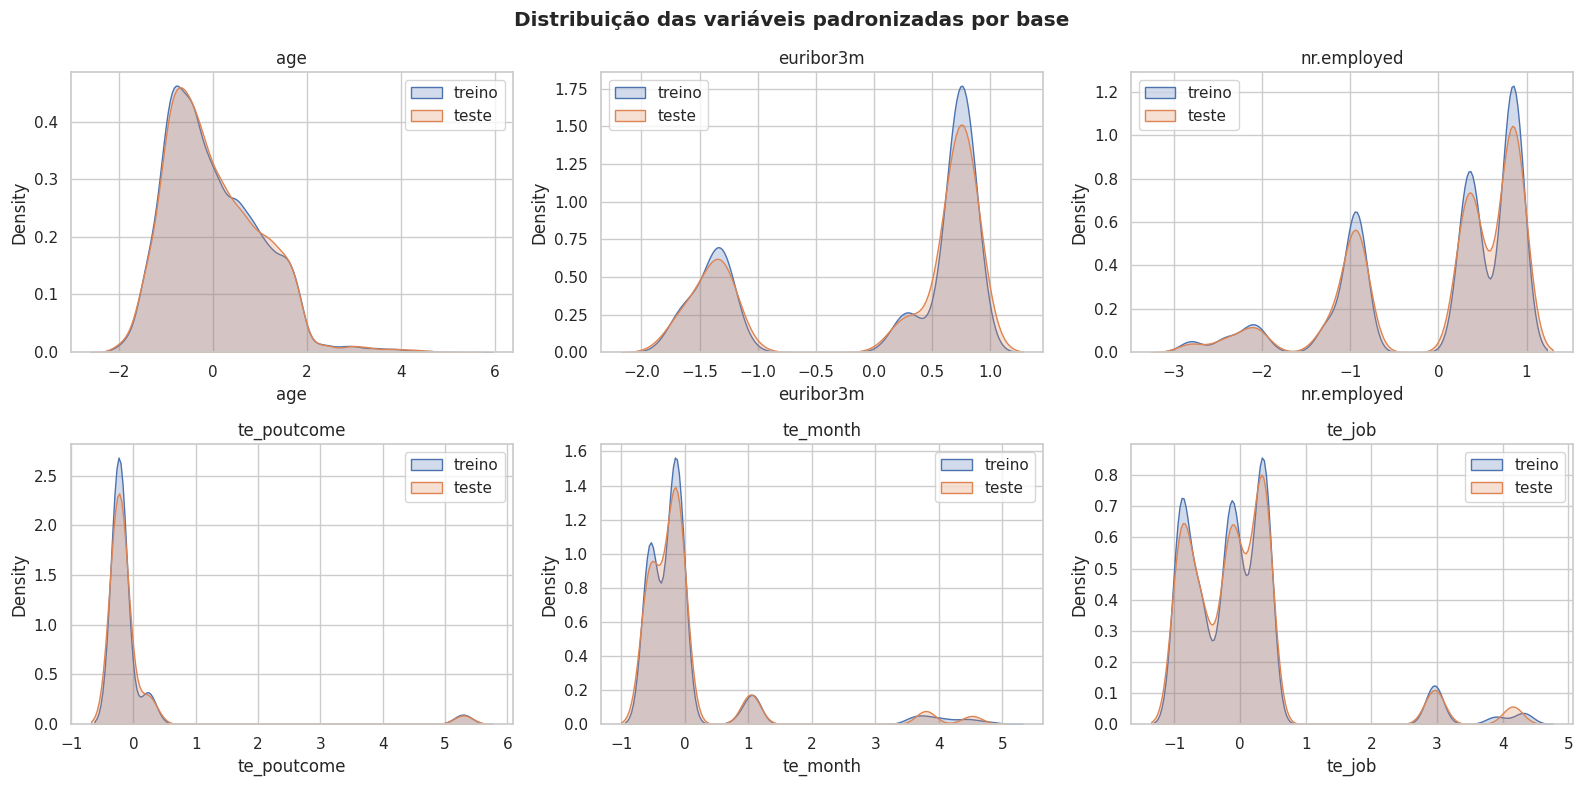

In [43]:
# Distribuição de treino x teste x OOT nas variáveis padronizadas (deslocamento do OOT fica visível)
cols_plot = ['age', 'euribor3m', 'nr.employed', 'te_poutcome', 'te_month', 'te_job']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cols_plot):
    for X, nome in [(X_treino, 'treino'), (X_teste, 'teste')]:
        sns.kdeplot(X[c], ax=ax, label=nome, fill=True, alpha=.25, warn_singular=False)
    ax.set_title(c); ax.legend()
plt.suptitle('Distribuição das variáveis padronizadas por base', fontweight='bold')
plt.tight_layout(); plt.show()

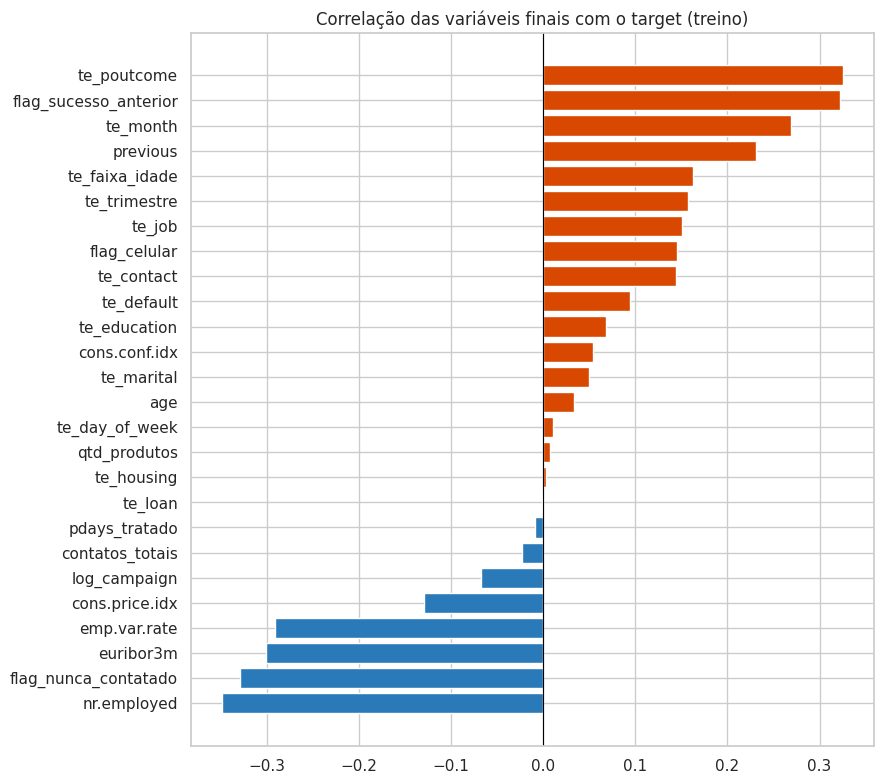

In [44]:
# Correlação das variáveis finais com o target (no treino)
corr = pd.concat([X_treino, y_treino], axis=1).corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(corr.index, corr.values, color=['#d94801' if v > 0 else '#2a7ab9' for v in corr.values])
ax.axvline(0, color='black', lw=.8)
ax.set_title('Correlação das variáveis finais com o target (treino)')
plt.tight_layout(); plt.show()

## 10. Salvar bases e transformadores

In [45]:
for nome, X, y, d in [('treino', X_treino, y_treino, df_treino),
                      ('teste', X_teste, y_teste, df_teste)]:
    saida = X.copy()
    saida[TARGET] = y.values
    saida['AnoMes'] = d['AnoMes'].values
    saida.to_parquet(f'{PASTA_SAIDA}/{nome}.parquet', index=False)

# Transformadores ajustados no treino (para escorar bases novas do mesmo jeito)
joblib.dump({
    'medianas': medianas, 'modas': modas, 'target_encoder': te, 'scaler': scaler,
    'COLS_CAT': COLS_CAT, 'COLS_NUM': COLS_NUM, 'COLS_FLAG': COLS_FLAG,
    'COLS_TE': COLS_TE, 'COLS_ESCALAR': COLS_ESCALAR, 'FEATURES': FEATURES,
    'metadados_treino': metadados_treino,
}, f'{PASTA_SAIDA}/transformadores_prep.joblib')

metadados_treino.to_csv(f'{PASTA_SAIDA}/metadados_treino.csv')

print('Arquivos salvos em', PASTA_SAIDA)
print(os.listdir(PASTA_SAIDA))

Arquivos salvos em /content/drive/MyDrive/PoD_Academy/Modelagem/Problema Propensao Compra Produto Bancario/Base/prep
['metadados_treino.csv', 'teste.parquet', 'treino.parquet', 'oot.parquet', 'transformadores_prep.joblib', 'variaveis_selecionadas.json', 'tabela_selecao_variaveis.csv']


## Resumo

| Etapa | Decisão |
|---|---|
| Duplicatas | Removidas |
| `duration` | Removida (vazamento) |
| `AnoMes` | Reconstruída da ordem das linhas; usada só para o split |
| `pdays = 999` | `flag_nunca_contatado` + `pdays_tratado` (NaN → mediana) |
| `unknown` | Moda do treino, exceto `default` (mantido como categoria) |
| Categóricas | Target Encoding com cross-fitting (5 folds) e suavização |
| Escala | `log1p` em `campaign` + StandardScaler (flags ficam 0/1) |
| Split | OOT ≥ 200906 · treino/teste 70/30 estratificado até 200905 |

**Próximo passo:** `03_modelagem.ipynb`, lendo `treino.parquet`, `teste.parquet` e `oot.parquet`.